Explorational Analysis

In [1]:
import logging

import matplotlib.pyplot as plt
import pandas as pd

from cwfc.split import split_holdout
from cwfc.targets import build_targets

logging.basicConfig(level=logging.INFO)

readings = pd.read_csv("../challenge_data/vm_cpu_readings.csv.gz")
metadata = pd.read_csv("../challenge_data/vm_metadata.csv.gz")

targets = build_targets(readings)
train, holdout_timestamps = split_holdout(targets)

train_readings = readings[readings["timestamp"].isin(train["timestamp"])]

INFO:cwfc.targets:Dropped 0 of 1340000 rows


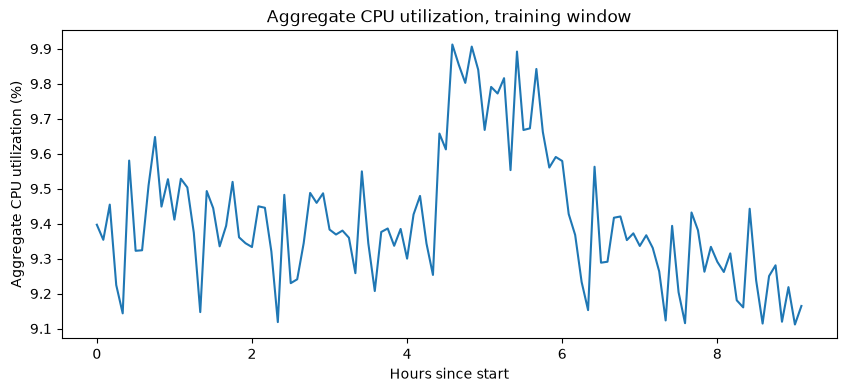

In [8]:
hours = train["timestamp"] / 3600

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(hours, train["aggregate_cpu_utilization"])
ax.set_xlabel("Hours since start")
ax.set_ylabel("Aggregate CPU utilization (%)")
ax.set_title("Aggregate CPU utilization, training window")
plt.show()

In [9]:
train.iloc[40:56][["timestamp", "aggregate_cpu_utilization"]]

,timestamp,aggregate_cpu_utilization
40,12000,9.258377
41,12300,9.549447
42,12600,9.343735
43,12900,9.207312
44,13200,9.376121
45,13500,9.386168
46,13800,9.336650
47,14100,9.384814
48,14400,9.299893
49,14700,9.426354


In [3]:
train.loc[train["aggregate_cpu_utilization"].idxmax()]

timestamp                    16500.000000
active_vm_count              10000.000000
aggregate_cpu_utilization        9.912175
Name: 55, dtype: float64

In [4]:
train["aggregate_cpu_utilization"].median()

np.float64(9.378120946203444)

In [6]:
hours_r = train_readings["timestamp"] / 3600
in_spike = hours_r.between(4, 6)

per_vm = train_readings.groupby(["vm_id", in_spike])["avg_cpu"].mean().unstack()
increase = (per_vm[True] - per_vm[False]).sort_values(ascending=False)

share_top = increase.head(10).sum() / increase.sum()
share_top

np.float64(0.14142693517167107)

In [7]:
increase.head(100).sum() / increase.sum()

np.float64(0.7842163064379386)

Finding: Aggregate CPU stays in a narrow band around its median of 9.38% with no visible trend: the level before hour 4 and after hour 6 is about the same. The largest deviation is a bump between hours 4 and 6, peaking at 9.91% at hour 4.6 (step 55), about 0.53 points (~6%) above the median. A slow rise precedes it, but the jump itself is abrupt.

The bump is driven by a small group of VMs: comparing each VM’s mean CPU inside and outside that window, the top 10 VMs (0.1%) account for about 14% of the increase and the top 100 (1%) for about 78%.

Why it matters: Bursts from a few workloads give only a weak early signal in the aggregate history, so a forecast based on past values will tend to under-predict them. The capacity margin should therefore come from the forecast’s uncertainty, not from the point forecast alone.